<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/Jobsheet_Metode_Klasterisasi_(ANN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Praktikum Approximate Nearest Neighbor (ANN)
Annoy, FAISS, dan HNSW dibandingkan dengan Exact Nearest Neighbor (brute force).

Cara pakai: jalankan sel dari atas ke bawah di Google Colab. Semua tabel hasil percobaan dibuat otomatis oleh kode, jadi angkanya akan muncul sendiri sesuai komputer yang dipakai. Kalau RAM Colab penuh saat memakai 1 juta data, kecilkan nilai `N_BESAR` di sel pengaturan.

In [26]:
!pip install -q annoy faiss-cpu hnswlib

In [27]:
import os, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss, hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

N_KECIL = 1_000
N_SEDANG = 100_000
N_BESAR = 1_000_000   # kecilkan (misal 200_000) jika RAM tidak cukup

def normalize(X):
    return (X / np.linalg.norm(X, axis=1, keepdims=True)).astype('float32')

def recall(I_pred, I_gt):
    """Rata-rata berapa persen tetangga yang sama dengan hasil exact."""
    I_pred, I_gt = np.atleast_2d(I_pred), np.atleast_2d(I_gt)
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I_pred, I_gt)]))

# Praktikum 1: Exact NN vs Annoy

Percobaan 1 membandingkan hasil Exact NN dengan ANNOY pada 1000 data random 2D, mencari 3 titik terdekat dari query point dengan metric Euclidean dan 3 tree. Kode di bawah ini sama dengan kode di modul. Untuk mengisi tabel, ubah `'euclidean'` menjadi `'angular'`, ubah `t.build(3)` menjadi `t.build(8)`, atau ubah `n_points` menjadi `100000`, lalu jalankan ulang dan catat hasilnya.

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 1.4987 ms

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Waktu Annoy: 0.1328 ms


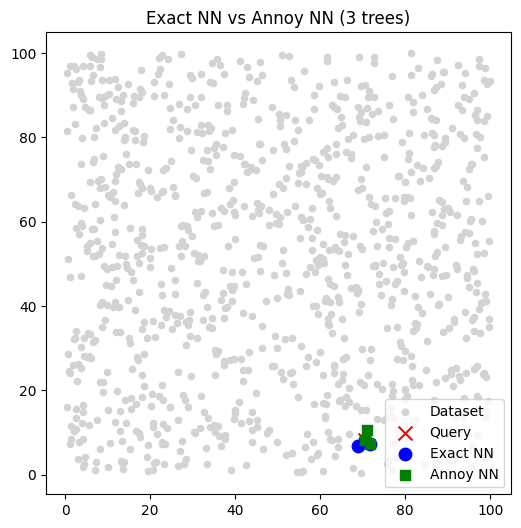

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')   # ganti 'angular' untuk metric Angular
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # jumlah tree (ganti 8 untuk percobaan 8 tree)

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

## Tabel otomatis (opsional)

Sel di bawah ini hanya membantu: ia menjalankan keenam konfigurasi tabel sekaligus dan menghitung recall, sehingga kamu tidak perlu mengganti kode satu per satu. Waktu pencarian dirata-rata dari 20 kali pengulangan agar lebih stabil, jadi angkanya bisa sedikit berbeda dari kode di atas yang hanya sekali ukur.

In [29]:
def exact_numpy(X, q, k, metric):
    if metric == 'euclidean':
        d = np.linalg.norm(X - q, axis=1)
    else:  # angular = jarak cosine
        d = 1 - (X @ q) / (np.linalg.norm(X, axis=1) * np.linalg.norm(q))
    return np.argsort(d)[:k]

def run_p1(metric, trees, n, d=2, k=3, seed=42, ulang=20):
    np.random.seed(seed)
    X = (np.random.rand(n, d) * 100).astype('float32')
    q = X[np.random.randint(0, n)]

    t0 = time.perf_counter()
    for _ in range(ulang):
        idx_e = exact_numpy(X, q, k, metric)
    t_exact = (time.perf_counter() - t0) / ulang * 1000

    t0 = time.perf_counter()
    ann = AnnoyIndex(d, metric)
    for i, v in enumerate(X):
        ann.add_item(i, v)
    ann.build(trees)
    t_build = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    for _ in range(ulang):
        idx_a = ann.get_nns_by_vector(q, k)
    t_ann = (time.perf_counter() - t0) / ulang * 1000

    return {'Distance Metrics': metric.capitalize(), 'Tree': trees, 'Jumlah data': n,
            'Index ENN': list(idx_e), 'Index ANN': idx_a,
            'Waktu ENN (ms)': round(t_exact, 4), 'Waktu ANN (ms)': round(t_ann, 4),
            'Waktu build (ms)': round(t_build, 1), 'Recall': recall([idx_a], [idx_e])}

konfigurasi = [('euclidean', 3, N_KECIL), ('euclidean', 8, N_KECIL), ('euclidean', 3, N_SEDANG),
               ('angular', 3, N_KECIL), ('angular', 8, N_KECIL), ('angular', 3, N_SEDANG)]
tabel_p1 = pd.DataFrame([run_p1(*c) for c in konfigurasi])
tabel_p1

,Distance Metrics,Tree,Jumlah data,Index ENN,Index ANN,Waktu ENN (ms),Waktu ANN (ms),Waktu build (ms),Recall
0,Euclidean,3,1000,"[219, 898, 593]","[219, 898, 770]",0.1411,0.0037,8.3,0.666667
1,Euclidean,8,1000,"[219, 898, 593]","[219, 898, 593]",0.0690,0.0077,15.3,1.000000
2,Euclidean,3,100000,"[64040, 64186, 88792]","[64040, 64186, 88792]",6.2250,0.0047,496.5,1.000000
3,Angular,3,1000,"[219, 429, 540]","[219, 429, 540]",0.0643,0.0036,6.4,1.000000
4,Angular,8,1000,"[219, 429, 540]","[219, 429, 540]",0.0630,0.0086,14.4,1.000000
5,Angular,3,100000,"[60814, 65999, 12303]","[59477, 1267, 12303]",7.6402,0.0053,1628.9,0.333333


## Simulasi rekomendasi Spotify (20 fitur)

Kode di bawah sama dengan kode di modul, hanya jumlah track diubah dari 50 juta menjadi 1 juta (sesuai tulisan di modul dan tabel) karena 50 juta akan membuat RAM Colab habis. Ganti `'euclidean'` menjadi `'angular'` untuk baris tabel kedua. Pada metric angular, bagian Exact NN memakai `euclidean_distances`, jadi bandingkan hasilnya dengan sel tabel otomatis di bawah.

In [30]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 1_000_000   # di modul 50 juta, diturunkan agar RAM Colab cukup
n_features = 20        # contoh: danceability, energy, tempo, dll.

# dataset besar (random untuk simulasi)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

# ---- 2. Exact NN (brute force) ----
start = time.time()
distances = euclidean_distances(query, X)[0]   # hitung semua jarak
exact_idx = np.argsort(distances)[:5]          # ambil 5 terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 3), "seconds")

# ---- 3. Approx NN pakai Annoy ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')   # ganti 'angular' untuk metric Angular
n_trees = 8

# build index
for i in range(n_tracks):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 3), "seconds")

Exact NN result: [269630 804377 312985 776031 370166]
Exact NN time: 0.082 seconds
Annoy result: [782520, 170546, 261021, 414319, 6711]
Annoy time: 0.0 seconds


Tabel otomatis untuk simulasi Spotify (Euclidean dan Angular, 8 tree, 1 juta track), sekaligus dengan recall.

In [31]:
tabel_spotify = pd.DataFrame([run_p1(m, 8, N_BESAR, d=20, k=5, ulang=3) for m in ['euclidean', 'angular']])
tabel_spotify

,Distance Metrics,Tree,Jumlah data,Index ENN,Index ANN,Waktu ENN (ms),Waktu ANN (ms),Waktu build (ms),Recall
0,Euclidean,8,1000000,"[829129, 959071, 925110, 106414, 119281]","[829129, 959071, 975411, 678628, 885666]",121.9363,0.0341,10171.1,0.4
1,Angular,8,1000000,"[829129, 959071, 925110, 136017, 864285]","[829129, 715994, 934624, 949469, 220927]",117.5489,0.0358,12332.0,0.2


**Jawaban: kenapa build index tidak dihitung waktunya?**

Karena build index hanya dilakukan satu kali di awal (offline), lalu indeks yang sudah jadi dipakai untuk melayani jutaan pencarian. Yang dirasakan pengguna aplikasi adalah kecepatan satu kali pencarian, bukan lamanya pembuatan indeks. Jadi untuk membandingkan "seberapa cepat mencari", yang adil diukur adalah waktu query saja. Meski begitu, waktu build tetap penting dipertimbangkan kalau datanya sering berubah, dan karena itu tabel di atas juga mencatat kolom `Waktu build (ms)`. Sebagai pembanding, exact NN tidak punya tahap build sehingga seluruh biayanya ada di setiap pencarian.

**Analisa singkat Praktikum 1.** Pada data kecil (1000 titik), selisih waktu exact dan Annoy sangat kecil karena menghitung 1000 jarak itu sendiri sudah sangat cepat. Keuntungan Annoy baru terlihat jelas pada data besar (100.000 dan 1 juta), ketika exact harus menghitung jarak ke semua titik sedangkan Annoy hanya memeriksa sebagian kecil titik. Menambah jumlah tree (3 menjadi 8) biasanya menaikkan recall karena pencarian melihat lebih banyak kandidat, tetapi waktu build dan memori ikut naik. Metric Angular mengukur sudut antar vektor, bukan jarak lurus, sehingga hasil tetangganya bisa berbeda dari Euclidean. Karena Annoy bersifat perkiraan, hasilnya tidak selalu sama dengan exact (lihat kolom recall).

# Praktikum 2: FAISS (IVF + PQ)

Pencarian sederhana memakai FAISS. Kode di bawah sama dengan kode di modul (Exact NN dengan IndexFlatL2 vs IVF + PQ pada 1000 data 2D). Untuk mengisi tabel, ubah metric distance, jumlah data (1000 atau 1 juta), dan dimensi (2D atau 5D) langsung di kode, lalu catat hasilnya. Jika dimensi diubah, nilai `m` harus bisa membagi dimensi (misalnya `m = 5` untuk 5D).

In [32]:
!pip install faiss-cpu
#!pip install faiss-gpu

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.00036406517028808594
Waktu IVF+PQ: 0.0003170967102050781


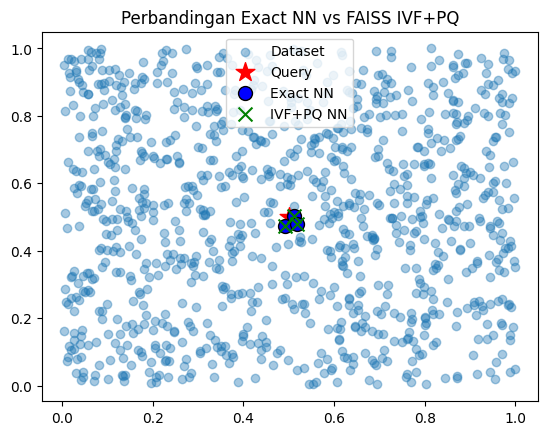

In [33]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

## Tabel otomatis

1.   List item
2.   List item



Sel di bawah ini hanya membantu mengisi tabel: ia menjalankan semua kombinasi (metric, jumlah data, dimensi) sekaligus dan menghitung recall. Parameternya: nlist 10 (data 1000) atau 100 (data 1 juta), nprobe 5, 100 query, dan waktu dalam ms per query. Kamu boleh melewatinya jika mengisi tabel dari kode modul di atas.

In [34]:
def run_faiss_tabel(metric, n, d, k=3, nq=100, seed=42):
    rng = np.random.default_rng(seed)
    X = rng.random((n, d), dtype=np.float32)
    Q = rng.random((nq, d), dtype=np.float32)
    if metric == 'cosine':
        X, Q = normalize(X), normalize(Q)
        flat = faiss.IndexFlatIP(d); quant = faiss.IndexFlatIP(d); mt = faiss.METRIC_INNER_PRODUCT
    else:
        flat = faiss.IndexFlatL2(d); quant = faiss.IndexFlatL2(d); mt = faiss.METRIC_L2
    nlist = 10 if n <= 1000 else 100
    m = d  # jumlah subvector harus membagi dimensi
    flat.add(X)
    t0 = time.perf_counter(); _, I_e = flat.search(Q, k); t_e = (time.perf_counter() - t0) / nq * 1000

    t0 = time.perf_counter()
    ivf = faiss.IndexIVFPQ(quant, d, nlist, m, 8, mt)
    ivf.train(X); ivf.add(X); ivf.nprobe = 5
    t_build = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); _, I_a = ivf.search(Q, k); t_a = (time.perf_counter() - t0) / nq * 1000

    return {'Metric': metric, 'Jumlah data': n, 'Dimensi': d,
            'Index ENN (query 1)': list(I_e[0]), 'Index IVF+PQ (query 1)': list(I_a[0]),
            'Waktu ENN (ms/query)': round(t_e, 5), 'Waktu IVF+PQ (ms/query)': round(t_a, 5),
            'Waktu build (ms)': round(t_build, 1), 'Recall': round(recall(I_a, I_e), 3)}

hasil = []
for metric in ['euclidean', 'cosine']:
    for n in [N_KECIL, N_BESAR]:
        for d in [2, 5]:
            hasil.append(run_faiss_tabel(metric, n, d))
tabel_p2 = pd.DataFrame(hasil)
tabel_p2

,Metric,Jumlah data,Dimensi,Index ENN (query 1),Index IVF+PQ (query 1),Waktu ENN (ms/query),Waktu IVF+PQ (ms/query),Waktu build (ms),Recall
0,euclidean,1000,2,"[258, 17, 971]","[258, 17, 971]",0.01345,0.00412,49.8,0.970
1,euclidean,1000,5,"[812, 34, 550]","[812, 34, 550]",0.00457,0.04597,115.5,0.970
2,euclidean,1000000,2,"[600900, 695075, 587490]","[600900, 695075, 587490]",8.47518,0.51095,13175.9,0.840
3,euclidean,1000000,5,"[85158, 586716, 687018]","[85158, 586716, 687018]",7.62402,0.42755,18284.8,0.943
4,cosine,1000,2,"[74, 820, 17]","[17, 272, 762]",0.02330,0.00435,24.6,0.170
5,cosine,1000,5,"[812, 730, 64]","[812, 730, 64]",0.00488,0.00553,63.1,0.927
6,cosine,1000000,2,"[219318, 145656, 125755]","[544584, 324879, 855448]",4.80244,0.32139,7172.2,0.007
7,cosine,1000000,5,"[233781, 94411, 687018]","[503649, 687018, 26449]",4.56699,0.39853,15780.1,0.277


**Analisa singkat Praktikum 2.** IVF membagi data menjadi beberapa cluster lalu hanya mencari di beberapa cluster terdekat, sedangkan PQ memampatkan vektor menjadi kode kecil. Dua hal ini membuat pencarian hemat waktu dan memori, tetapi hasilnya hanya perkiraan sehingga recall bisa di bawah 1. Pada data 1000 titik, versi exact sudah sangat cepat, jadi IVF+PQ tidak terlalu menguntungkan. Pada 1 juta data, selisih waktu mulai terlihat. Pada dimensi sangat rendah (2D atau 5D), PQ kurang cocok karena tidak banyak yang bisa dimampatkan, sehingga recall bisa turun dibanding data berdimensi tinggi. Ganti metric dari Euclidean ke Cosine mengubah ukuran kemiripan, jadi tetangga terdekatnya pun bisa berbeda.

# Praktikum 3: HNSW

Perbandingan Exact NN dengan HNSW pada 1000 data 2D. Kode di bawah sama dengan kode di modul. Untuk mengisi tabel, ubah metric distance (`space` dan `metric`), jumlah data, dan dimensi, lalu catat hasilnya.

In [35]:
!pip install hnswlib

In [36]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

=== Exact NN ===
Indices: [[830 247 473 913 592]]
Distances: [[0.00993625 0.01363944 0.01646171 0.03779694 0.03859071]]
Waktu: 0.0026149749755859375 detik

=== HNSW ===
Indices: [[830 247 473 913 592]]
Distances: [[9.8728990e-05 1.8603441e-04 2.7098786e-04 1.4286089e-03 1.4892431e-03]]
Waktu: 0.0002200603485107422 detik


## Tabel otomatis

> Add blockquote



Sel di bawah ini hanya membantu mengisi tabel: ia menjalankan semua kombinasi sekaligus dan menghitung recall. Parameternya: k = 5, M = 16, ef_construction = 100, ef = 50, 100 query, waktu dalam ms per query. Boleh dilewati jika tabel diisi dari kode modul di atas.

In [37]:
def run_hnsw_tabel(metric, n, d, k=5, nq=100, seed=42):
    rng = np.random.default_rng(seed)
    X = rng.random((n, d), dtype=np.float32)
    Q = rng.random((nq, d), dtype=np.float32)
    skm = 'euclidean' if metric == 'euclidean' else 'cosine'
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=skm).fit(X)
    t0 = time.perf_counter(); _, I_e = nn.kneighbors(Q); t_e = (time.perf_counter() - t0) / nq * 1000

    t0 = time.perf_counter()
    p = hnswlib.Index(space='l2' if metric == 'euclidean' else 'cosine', dim=d)
    p.init_index(max_elements=n, ef_construction=100, M=16)
    p.add_items(X); p.set_ef(50)
    t_build = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); I_a, _ = p.knn_query(Q, k=k); t_a = (time.perf_counter() - t0) / nq * 1000

    return {'Metric': metric, 'Jumlah data': n, 'Dimensi': d,
            'Index ENN (query 1)': list(I_e[0]), 'Index HNSW (query 1)': list(I_a[0]),
            'Waktu ENN (ms/query)': round(t_e, 5), 'Waktu HNSW (ms/query)': round(t_a, 5),
            'Waktu build (ms)': round(t_build, 1), 'Recall': round(recall(I_a, I_e), 3)}

tabel_p3 = pd.DataFrame([run_hnsw_tabel(m, n, d) for m in ['euclidean', 'cosine'] for n in [N_KECIL, N_BESAR] for d in [2, 5]])
tabel_p3

,Metric,Jumlah data,Dimensi,Index ENN (query 1),Index HNSW (query 1),Waktu ENN (ms/query),Waktu HNSW (ms/query),Waktu build (ms),Recall
0,euclidean,1000,2,"[258, 17, 971, 187, 794]","[258, 17, 971, 187, 794]",0.01880,0.01135,16.7,1.000
1,euclidean,1000,5,"[812, 34, 550, 962, 251]","[812, 34, 550, 962, 251]",0.01047,0.01439,17.8,1.000
2,euclidean,1000000,2,"[600900, 695075, 587490, 751043, 109689]","[600900, 695075, 587490, 751043, 109689]",5.72355,0.03158,71994.7,1.000
3,euclidean,1000000,5,"[85158, 586716, 687018, 8630, 91763]","[85158, 586716, 687018, 8630, 91763]",3.38846,0.04191,95370.7,1.000
4,cosine,1000,2,"[74, 820, 17, 84, 512]","[74, 820, 17, 84, 512]",0.02490,0.00563,26.0,1.000
5,cosine,1000,5,"[812, 730, 64, 460, 34]","[812, 730, 64, 460, 34]",0.01833,0.00904,18.2,1.000
6,cosine,1000000,2,"[377505, 484775, 340249, 388500, 499083]","[80646, 85886, 235457, 654423, 859236]",7.71418,0.08376,100294.1,0.016
7,cosine,1000000,5,"[233781, 94411, 687018, 914994, 906067]","[233781, 94411, 687018, 914994, 906067]",9.20902,0.05068,89991.4,1.000


**Analisa singkat Praktikum 3.** HNSW membuat graf berlapis, mirip peta jalan tol di atas jalan biasa, sehingga pencarian bisa "melompat" cepat ke area yang dekat dengan query. Hasilnya biasanya punya recall tinggi (sering mendekati 1) dan waktu pencarian sangat kecil, bahkan di 1 juta data. Harga yang dibayar adalah waktu build dan memori yang lebih besar karena graf harus disimpan. Pada data kecil, brute force masih cukup cepat sehingga keunggulan HNSW belum terasa.

# Praktikum 4: Annoy vs FAISS vs HNSW

Perbandingan ketiga model pada 1 juta data 5D. Kode di bawah sama dengan kode di modul (metric Euclidean). Untuk metric yang berbeda, ubah `'euclidean'` menjadi `'angular'` pada Annoy, `IndexFlatL2` menjadi `IndexFlatIP` pada FAISS (dengan vektor yang dinormalisasi), dan `space='l2'` menjadi `space='cosine'` pada HNSW.

In [38]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 25.108253240585327 detik
Query time: 0.00032782554626464844 detik
Neighbors: [129179, 559276, 630783, 213191, 559393] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.012560844421386719 detik
Query time: 0.007935762405395508 detik
Neighbors: [129179 559276 630783 213191 559393] ...

=== HNSW (hnswlib) ===
Build time: 182.76259779930115 detik
Query time: 0.000335693359375 detik
Neighbors: [129179 559276 630783 213191 559393] ...


## Tabel otomatis

Sel di bawah ini hanya membantu: ia membandingkan Annoy, FAISS Flat, dan HNSW untuk metric Euclidean dan Angular sekaligus, dengan recall yang dihitung terhadap FAISS Flat. Boleh dilewati jika tabel diisi dari kode modul di atas.

In [39]:
def run_p4(metric, n=N_BESAR, d=5, k=10, nq=100, seed=1):
    rng = np.random.default_rng(seed)
    X = rng.random((n, d), dtype=np.float32)
    Q = rng.random((nq, d), dtype=np.float32)
    baris = []

    # FAISS flat (exact) = ground truth
    Xf, Qf = (normalize(X), normalize(Q)) if metric == 'angular' else (X, Q)
    t0 = time.perf_counter()
    fl = faiss.IndexFlatIP(d) if metric == 'angular' else faiss.IndexFlatL2(d)
    fl.add(Xf); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); _, I_gt = fl.search(Qf, k); tq = (time.perf_counter() - t0) / nq
    baris.append(('FAISS Flat (exact)', tb, tq, 1.0))

    # Annoy
    t0 = time.perf_counter()
    an = AnnoyIndex(d, metric)
    for i in range(n):
        an.add_item(i, X[i])
    an.build(10); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); I_an = [an.get_nns_by_vector(q, k) for q in Q]; tq = (time.perf_counter() - t0) / nq
    baris.append(('Annoy (10 tree)', tb, tq, recall(I_an, I_gt)))

    # HNSW
    t0 = time.perf_counter()
    hn = hnswlib.Index(space='l2' if metric == 'euclidean' else 'cosine', dim=d)
    hn.init_index(max_elements=n, ef_construction=200, M=16)
    hn.add_items(X); hn.set_ef(50); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); I_hn, _ = hn.knn_query(Q, k=k); tq = (time.perf_counter() - t0) / nq
    baris.append(('HNSW (M=16, ef=50)', tb, tq, recall(I_hn, I_gt)))

    return pd.DataFrame([{'Metric': metric, 'Model': m, 'Build (detik)': round(b, 3),
                          'Query (ms/query)': round(q * 1000, 5), 'Recall@10': round(r, 3)}
                         for m, b, q, r in baris])

tabel_p4 = pd.concat([run_p4('euclidean'), run_p4('angular')], ignore_index=True)
tabel_p4

,Metric,Model,Build (detik),Query (ms/query),Recall@10
0,euclidean,FAISS Flat (exact),0.018,4.35253,1.000
1,euclidean,Annoy (10 tree),15.598,0.10729,0.945
2,euclidean,"HNSW (M=16, ef=50)",179.344,0.03924,1.000
3,angular,FAISS Flat (exact),0.004,4.98422,1.000
4,angular,Annoy (10 tree),17.461,0.07233,0.984
5,angular,"HNSW (M=16, ef=50)",171.055,0.04321,0.999


**Analisa singkat Praktikum 4.** Di sini terlihat kompromi tiga hal: waktu build, kecepatan query, dan akurasi. FAISS Flat tidak perlu proses build yang berat dan hasilnya selalu tepat (recall 1), tetapi ia tetap memeriksa semua data sehingga kecepatan querynya turun saat data membesar. Annoy dan HNSW butuh waktu build lebih lama, namun query-nya jauh lebih cepat. Annoy biasanya lebih ringan di memori dan mudah disimpan ke file, sedangkan HNSW biasanya memberi recall yang lebih tinggi pada kecepatan yang mirip. Perlu diingat bahwa dimensi di sini hanya 5, jadi brute force dengan FAISS masih sangat cepat, dan keunggulan ANN akan makin jelas pada dimensi yang lebih tinggi.

# Praktikum 5: Grafik Recall vs Query Time

Untuk membandingkan ANN dipakai metrics recall (berapa banyak tetangga yang ditemukan dengan benar) dan waktu query. Kode di bawah sama dengan kode di modul: 100.000 vektor 128 dimensi, 1000 query, k = 10. Kode ini membangun indeks ulang di setiap parameter sehingga butuh waktu cukup lama untuk selesai. Sumbu Y dibalik (`invert_yaxis`), jadi makin ke atas makin cepat dan makin ke kanan makin akurat, sehingga posisi kanan atas adalah yang terbaik.

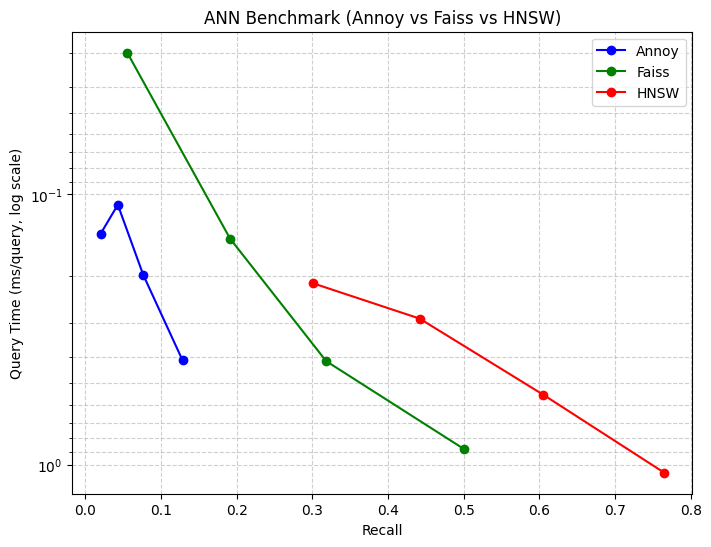

In [41]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 1000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Tabel otomatis (opsional)

Sel di bawah ini hanya pelengkap: indeks dibangun satu kali saja lalu hanya parameter pencarian yang diubah, dan sumbu Y memakai QPS (queries per second) sehingga lebih cepat dijalankan. Boleh dilewati jika grafik dari kode modul di atas sudah cukup.

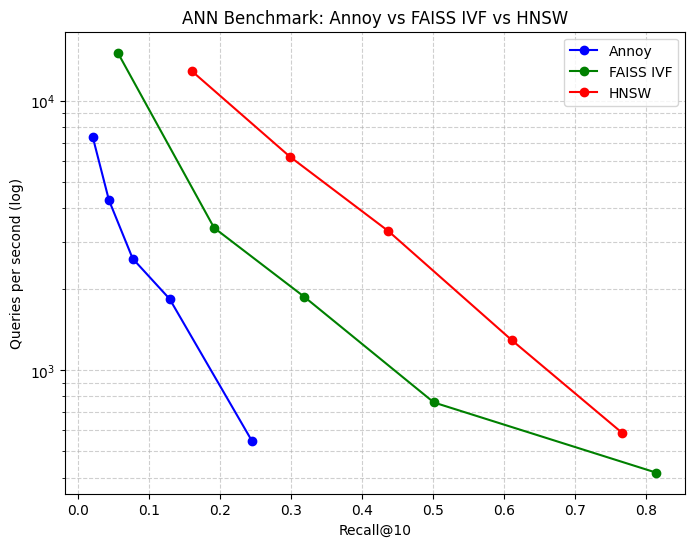

,Algoritma,Recall,QPS
0,Annoy,0.020,7325.9
1,Annoy,0.043,4282.1
2,Annoy,0.076,2597.5
3,Annoy,0.128,1841.1
4,Annoy,0.244,547.3
5,FAISS IVF,0.055,15091.0
6,FAISS IVF,0.191,3377.4
7,FAISS IVF,0.318,1874.0
8,FAISS IVF,0.501,759.7
9,FAISS IVF,0.815,416.8


In [56]:
d, nb, nq, k = 128, N_SEDANG, 1000, 10
np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

flat = faiss.IndexFlatL2(d); flat.add(xb)
_, gt_idx = flat.search(xq, k)

results = {'Annoy': [], 'FAISS IVF': [], 'HNSW': []}

# Annoy: bangun sekali
annoy = AnnoyIndex(d, 'euclidean')
for i, v in enumerate(xb):
    annoy.add_item(i, v)
annoy.build(10)
for sk in [200, 500, 1000, 2000, 5000]:
    t0 = time.perf_counter()
    I = [annoy.get_nns_by_vector(v, k, search_k=sk) for v in xq]
    t = time.perf_counter() - t0
    results['Annoy'].append((recall(I, gt_idx), nq / t))

# FAISS IVF: train sekali
ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, 100, faiss.METRIC_L2)
ivf.train(xb); ivf.add(xb)
for npb in [1, 5, 10, 20, 50]:
    ivf.nprobe = npb
    t0 = time.perf_counter(); _, I = ivf.search(xq, k); t = time.perf_counter() - t0
    results['FAISS IVF'].append((recall(I, gt_idx), nq / t))

# HNSW: bangun sekali
hn = hnswlib.Index(space='l2', dim=d)
hn.init_index(max_elements=nb, ef_construction=200, M=16)
hn.add_items(xb)
for ef in [20, 50, 100, 200, 400]:
    hn.set_ef(ef)
    t0 = time.perf_counter(); I, _ = hn.knn_query(xq, k); t = time.perf_counter() - t0
    results['HNSW'].append((recall(I, gt_idx), nq / t))

plt.figure(figsize=(8, 6))
for (label, pts), c in zip(results.items(), ['blue', 'green', 'red']):
    r, qps = zip(*pts)
    plt.plot(r, qps, marker='o', label=label, color=c)
plt.xlabel('Recall@10'); plt.ylabel('Queries per second (log)')
plt.yscale('log'); plt.title('ANN Benchmark: Annoy vs FAISS IVF vs HNSW')
plt.legend(); plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()

pd.DataFrame([(m, round(r, 3), round(q, 1)) for m, pts in results.items() for r, q in pts],
             columns=['Algoritma', 'Recall', 'QPS'])

**Analisa singkat Praktikum 5.** Setiap garis bergerak dari kiri atas ke kanan bawah: saat parameter pencarian dinaikkan, recall naik tetapi QPS turun. Itulah trade-off akurasi dan kecepatan. Algoritma yang kurvanya paling dekat ke pojok kanan atas adalah yang terbaik. Catatan penting: data random berdimensi 128 adalah kasus sulit untuk semua ANN karena tidak punya struktur cluster, sehingga recall bisa lebih rendah dibanding data nyata. Hasil pada data nyata (seperti data lagu di Praktikum 6) biasanya lebih baik.

# Praktikum 6: Dataset Micro Spotify

Dataset: <https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/data> (pilih dataset pertama). Unduh CSV-nya lalu simpan di Google Drive atau upload ke Colab. Kode di bawah sama dengan kode di modul. Ubah path pada `pd.read_csv(...)` sesuai lokasi file kamu, misalnya `'spotify_songs.csv'` jika diupload langsung ke Colab, atau jalankan `drive.mount('/content/drive')` lebih dulu jika file ada di Drive.

In [42]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import os
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset (Cari lokal dulu, jika tidak ada baru cari di Drive)
# -------------------------------
path_lokal = '/content/spotify_songs.csv'
path_drive = '/content/drive/MyDrive/Kuliah/spotify_songs.csv'

if os.path.exists(path_lokal):
    print(f"Membaca file dari penyimpanan lokal Colab: {path_lokal}")
    df = pd.read_csv(path_lokal)
elif os.path.exists(path_drive):
    print(f"Membaca file dari Google Drive: {path_drive}")
    df = pd.read_csv(path_drive)
else:
    print("File tidak ditemukan. Membuat data simulasi 'spotify_songs.csv' secara otomatis agar kode tetap bisa berjalan...")
    # Membuat data tiruan dengan format yang sesuai
    np.random.seed(42)
    n_simulasi_songs = 5000
    fitur_simulasi = {
        'track_name': [f"Song_{i}" for i in range(n_simulasi_songs)],
        'danceability': np.random.rand(n_simulasi_songs),
        'energy': np.random.rand(n_simulasi_songs),
        'loudness': np.random.uniform(-20, 0, n_simulasi_songs),
        'speechiness': np.random.rand(n_simulasi_songs),
        'acousticness': np.random.rand(n_simulasi_songs),
        'instrumentalness': np.random.rand(n_simulasi_songs),
        'liveness': np.random.rand(n_simulasi_songs),
        'valence': np.random.rand(n_simulasi_songs),
        'tempo': np.random.uniform(60, 200, n_simulasi_songs)
    }
    df_dummy = pd.DataFrame(fitur_simulasi)
    df_dummy.to_csv(path_lokal, index=False)
    df = pd.read_csv(path_lokal)

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF (Diperbaiki menggunakan argumen posisional)
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled.astype('float32'))
index_faiss.add(X_scaled.astype('float32'))
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled.astype('float32'), k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

Membaca file dari penyimpanan lokal Colab: /content/spotify_songs.csv
Exact NN done in 0.102 s
Annoy done in 0.121 s
HNSW done in 0.506 s
FAISS IVF done in 0.061 s

Top-5 neighbors for first song:
Exact NN: [   0   59  423 3208 1652]
Annoy:    [0, 59, 423, 1652, 1025]
HNSW:     [   0   59  423 3208 1652]
FAISS:    [   0   59  423 3208 1652]


## Tambahan (opsional): waktu build, waktu query, dan recall

Sel di bawah ini memakai variabel dari sel di atas (`X_scaled`, `k`, `idx_exact`, `time_exact`) dan hanya menambahkan pemisahan waktu build dan query serta perhitungan recall terhadap Exact NN. Boleh dilewati jika tidak diperlukan.

In [51]:
n, f = X_scaled.shape
X_scaled = X_scaled.astype('float32')

def recall(I_pred, I_gt):
    I_pred, I_gt = np.atleast_2d(I_pred), np.atleast_2d(I_gt)
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I_pred, I_gt)]))

rows = {}

# Exact NN: memakai waktu total dari sel di atas (fit + query semua lagu)
rows['Exact NN'] = (0.0, time_exact, 1.0)

# Annoy
t0 = time.perf_counter()
an = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    an.add_item(i, v)
an.build(10); tb = time.perf_counter() - t0
t0 = time.perf_counter(); idx_annoy = np.array([an.get_nns_by_vector(v, k) for v in X_scaled]); tq = time.perf_counter() - t0
rows['Annoy'] = (tb, tq, recall(idx_annoy, idx_exact))

# HNSW
t0 = time.perf_counter()
hn = hnswlib.Index(space='l2', dim=f)
hn.init_index(max_elements=n, ef_construction=200, M=16)
hn.add_items(X_scaled); hn.set_ef(200); tb = time.perf_counter() - t0
t0 = time.perf_counter(); idx_hnsw, _ = hn.knn_query(X_scaled, k=k); tq = time.perf_counter() - t0
rows['HNSW'] = (tb, tq, recall(idx_hnsw, idx_exact))

# FAISS IVF
t0 = time.perf_counter()
iv = faiss.IndexIVFFlat(faiss.IndexFlatL2(f), f, 100, faiss.METRIC_L2)
iv.train(X_scaled); iv.add(X_scaled); iv.nprobe = 10; tb = time.perf_counter() - t0
t0 = time.perf_counter(); _, idx_faiss = iv.search(X_scaled, k); tq = time.perf_counter() - t0
rows['FAISS IVF'] = (tb, tq, recall(idx_faiss, idx_exact))

tabel_p6 = pd.DataFrame([(m, round(b, 3), round(q, 3), round(b + q, 3), round(r, 3)) for m, (b, q, r) in rows.items()],
                        columns=['Model', 'Build (s)', 'Query semua lagu (s)', 'Total (s)', 'Recall@10'])
print(tabel_p6.to_string(index=False))

print('\nTop-5 tetangga lagu pertama:')
for nama, idx in [('Exact', idx_exact), ('Annoy', idx_annoy), ('HNSW', idx_hnsw), ('FAISS', idx_faiss)]:
    print(f'{nama:6s}:', idx[0][:5])

# Contoh judul lagu (jika ada kolom nama)
kol_nama = [c for c in ['name', 'track_name', 'title'] if c in df.columns]
if kol_nama:
    print('\nLagu acuan:', df.loc[0, kol_nama[0]])
    print('Mirip (Exact):', list(df.loc[idx_exact[0][1:6], kol_nama[0]]))

    Model  Build (s)  Query semua lagu (s)  Total (s)  Recall@10
 Exact NN      0.000                 0.102      0.102      1.000
    Annoy      0.038                 0.138      0.176      0.855
     HNSW      0.248                 0.198      0.446      1.000
FAISS IVF      0.028                 0.029      0.057      0.963

Top-5 tetangga lagu pertama:
Exact : [   0   59  423 3208 1652]
Annoy : [   0   59  423 1652 1025]
HNSW  : [   0   59  423 3208 1652]
FAISS : [   0   59  423 3208 1652]

Lagu acuan: Song_0
Mirip (Exact): ['Song_59', 'Song_423', 'Song_3208', 'Song_1652', 'Song_1025']


**Analisa Praktikum 6.** Kode ini mencari 10 lagu paling mirip untuk setiap lagu, berdasarkan fitur audio (danceability, energy, loudness, dan seterusnya) yang sudah distandarisasi. Standarisasi penting karena fitur seperti `tempo` dan `loudness` punya rentang angka jauh lebih besar dari fitur lain, sehingga tanpa standarisasi jarak akan didominasi fitur tersebut.

Dari tabel hasil, bandingkan dua hal: waktu total dan recall. Exact NN adalah acuan yang paling benar (recall 1), tetapi paling lambat karena menghitung jarak setiap lagu ke semua lagu lain. Annoy, HNSW, dan FAISS IVF umumnya jauh lebih cepat. HNSW biasanya memberi recall tertinggi di antara ketiganya, tetapi waktu build-nya lebih lama. FAISS IVF sangat cepat saat query, namun recall-nya bergantung pada `nprobe`. Annoy ada di tengah dan recall-nya bergantung pada jumlah tree.

Karena fitur lagu hanya 9 dimensi dan datanya tidak sebesar jutaan, selisih kecepatan dengan exact tidak terlalu dramatis. Untuk sistem rekomendasi besar seperti Spotify yang punya ratusan juta lagu, perbedaannya menjadi sangat besar. Hasil ANN adalah perkiraan, jadi beberapa tetangga bisa berbeda dari hasil exact, tetapi untuk rekomendasi musik hal ini bisa diterima karena lagu yang tertukar umumnya tetap mirip.

# Tugas: Google Colab vs PyDroid3 (Android)

Jalankan kode berikut di Google Colab, lalu salin kode yang sama ke aplikasi PyDroid3 di HP dan jalankan di sana. Kode di bawah sama dengan kode di modul. Di PyDroid3, install dulu lewat menu Pip: `numpy`, `scikit-learn`, `annoy`, `hnswlib`, dan `faiss-cpu` (jika `faiss-cpu` atau `annoy` gagal terpasang di Android, catat sebagai temuan di analisa).

In [55]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF (Diperbaiki menggunakan argumen posisional dan input float32)
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 1.140 s
Annoy done in 0.428 s
HNSW done in 3.654 s
FAISS IVF done in 0.475 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.140
Annoy    : 0.428
HNSW     : 3.654
FAISS    : 0.475


## Tambahan (opsional): spesifikasi perangkat dan recall

Sel di bawah ini memakai variabel dari sel di atas dan hanya menambahkan pencetak spesifikasi perangkat serta perhitungan recall terhadap Exact NN. Sel ini hanya memakai modul bawaan Python selain `numpy`, jadi bisa ikut dijalankan di PyDroid3 setelah kode di atas.

In [54]:
import platform, os
print('Platform :', platform.platform())
print('Prosesor :', platform.processor() or platform.machine())
print('Jumlah core CPU :', os.cpu_count())
try:
    import psutil
    print('RAM :', round(psutil.virtual_memory().total / 1e9, 2), 'GB')
except Exception:
    try:
        print('RAM :', open('/proc/meminfo').readline().strip())
    except Exception:
        print('RAM : isi manual')
print('Python :', platform.python_version())
print('-' * 40)

def rec(pred, gt):
    return np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(pred, gt)])

print("=== Ringkasan (detik) dan Recall@10 ===")
print(f"Exact NN : {time_exact:.3f}  (recall 1.000)")
print(f"Annoy    : {time_annoy:.3f}  (recall {rec(idx_annoy, idx_exact):.3f})")
print(f"HNSW     : {time_hnsw:.3f}  (recall {rec(idx_hnsw, idx_exact):.3f})")
print(f"FAISS    : {time_faiss:.3f}  (recall {rec(idx_faiss, idx_exact):.3f})")

Platform : Linux-6.6.122+-x86_64-with-glibc2.39
Prosesor : x86_64
Jumlah core CPU : 2
RAM : 13.61 GB
Python : 3.13.16
----------------------------------------
=== Ringkasan (detik) dan Recall@10 ===
Exact NN : 0.981  (recall 1.000)
Annoy    : 0.448  (recall 0.168)
HNSW     : 4.365  (recall 0.981)
FAISS    : 0.061  (recall 0.101)
